# Motif candidates from a Gaussian mixture in the full 10-band space

Mouse 720762, deep prelimbic LFP (PL5), the 10 overlapping bands of the 2026-11-01 report.

**Idea.** Every second is a point in 10-D band space (one z-scored envelope value per band). Instead of finding motif
axes first (binarize, cluster, PCA) and then looking along them, fit a Gaussian mixture (GMM) directly to the points.
Each component is a cloud of seconds; its **mean is a candidate motif** (a band pattern), and its **responsibility**
(probability that a second belongs to it) is that motif's expression over time. Nothing forces components to come in
opposite pairs, so asymmetric "opponents", a baseline cloud near zero, or 3+ distinct states can all show up.

**How many components?** Seconds are strongly autocorrelated (5-s smoothing), so BIC overcounts. We use:
- **held-out log-likelihood**: fit on 4/5 of the time, score the remaining contiguous fifth (10 s trimmed at its edges);
- a **phase-randomized surrogate**: same random Fourier phases for all bands, which keeps every band's autocorrelation
  and every pair of bands' correlation but has no clusters. *Excess* = how much more the real data gains from K
  components than the surrogate does. Excess near 0 means "just correlated Gaussian noise".

**Time bins** (z-scored within each bin):

| bin | what |
|---|---|
| awake | spontaneous awake (electrical and visual stimulus blocks removed) |
| isoflurane | spontaneous isoflurane maintenance |
| awake_all | all awake time, stimuli included |
| iso_all | all isoflurane maintenance, stimuli included |
| full | whole recording up to isoflurane off |

Section 6 revisits the GMM *along a motif axis*, since the axis projections are often bimodal.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from diptest import diptest
from sklearn.mixture import GaussianMixture

sys.path.insert(0, "..")
from src import candidate_motifs as cm
from src import gmm_motifs as gx
from src import session_data as sd
from src.state_motifs import band_labels, minority_sign_bands
%matplotlib inline

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-09_gmm_motifs"
OUT.mkdir(parents=True, exist_ok=True)
names = band_labels()
KS = list(range(1, 11))

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")

io, nwb = sd.open_nwb(NWB)
beh = nwb.processing["behavior"]
rs = beh["BehavioralTimeSeries"]["running_speed"]
run_speed = rs.data[:]
run_t = rs.timestamps[:] if rs.timestamps is not None else rs.starting_time + np.arange(run_speed.size) / rs.rate
pw = beh["PupilTracking"]["pupil_width"]
pupil, pupil_t = pw.data[:], pw.timestamps[:]
io.close()

info, t, env = cm.signal_envelope(NWB, ("lfp", "probeF", "PL5"))
bins = cm.time_bins(info)
E = cm.EDGE
bins["awake_all"] = [(info.t_start + E, info.iso_on - 30)]
bins["iso_all"] = [(info.induction_end + E, info.iso_off - E)]
bins["full"] = [(info.t_start + E, info.iso_off - E)]
BINS = ["awake", "isoflurane", "awake_all", "iso_all", "full"]
data = {b: cm.bin_pieces(t, env, bins[b]) for b in BINS}
pd.Series({b: sum(len(tt) for tt, _ in data[b]) for b in BINS}, name="seconds").to_frame().T

,awake,isoflurane,awake_all,iso_all,full
seconds,947,1388,3238,3662,7088


## 1. How many components does each bin support?

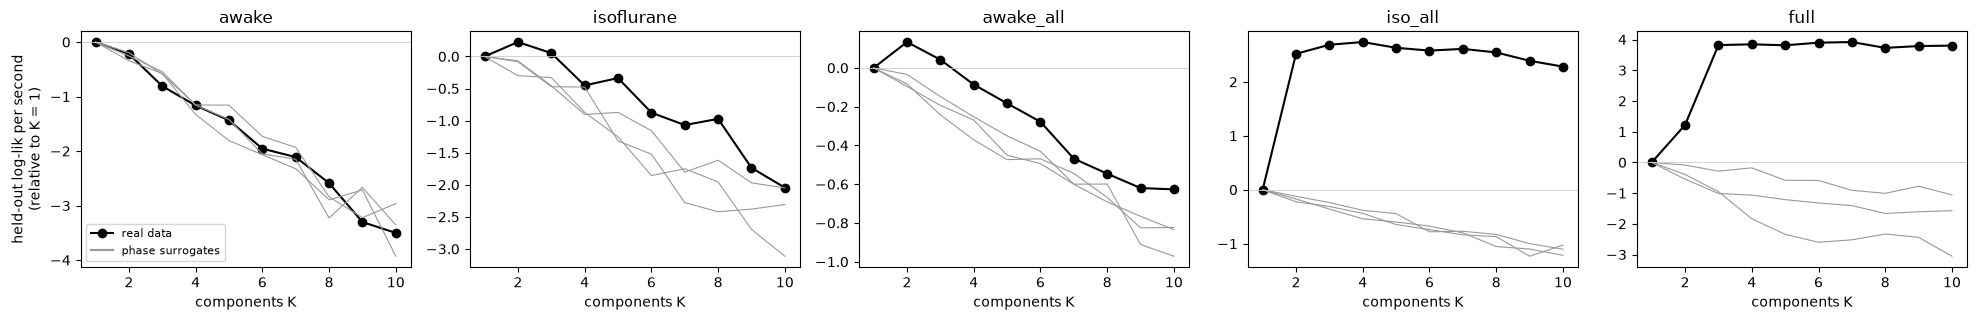

,best K (held-out),gain at best K,surrogate gain at that K,excess at best K
awake,1.0,0.00,0.00,0.00
isoflurane,2.0,0.22,-0.15,0.37
awake_all,2.0,0.13,-0.07,0.20
iso_all,4.0,2.74,-0.45,3.19
full,7.0,3.92,-1.61,5.53


In [2]:
N_SUR = 3
curves = {}
for b in BINS:
    pieces = [z for _, z in data[b]]
    real, real_folds = gx.cv_loglik(pieces, KS)
    sur = np.array([gx.cv_loglik(gx.phase_surrogate(pieces, np.random.default_rng(s)), KS)[0] for s in range(N_SUR)])
    curves[b] = (real, sur)

fig, axes = plt.subplots(1, len(BINS), figsize=(4 * len(BINS), 3.3), sharex=True)
for ax, b in zip(axes, BINS):
    real, sur = curves[b]
    ax.plot(KS, real - real[0], "o-", color="k", label="real data")
    for s in sur:
        ax.plot(KS, s - s[0], color="0.6", lw=0.8)
    ax.plot([], [], color="0.6", label="phase surrogates")
    ax.axhline(0, color="0.8", lw=0.6)
    ax.set_title(b); ax.set_xlabel("components K")
axes[0].set_ylabel("held-out log-lik per second\n(relative to K = 1)")
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "1_choose_k"); plt.show()

rows = {}
for b in BINS:
    real, sur = curves[b]
    excess = (real - real[0]) - (sur - sur[:, :1]).mean(axis=0)
    rows[b] = {"best K (held-out)": KS[int(real.argmax())], "gain at best K": real.max() - real[0],
               "surrogate gain at that K": (sur[:, real.argmax()] - sur[:, 0]).mean(),
               "excess at best K": excess[real.argmax()]}
choose = pd.DataFrame(rows).T
choose.round(2)

Read: a curve above the grey lines means more cluster structure than correlated Gaussian noise. The chosen K for
each bin is where the real curve peaks (held-out data stop improving).

## 2. The candidate motifs (component means)

In [3]:
K_BEST = {b: int(choose.loc[b, "best K (held-out)"]) for b in BINS}
models, labels, resps, Zs, Ts = {}, {}, {}, {}, {}
relaxed_poles = {}
for b in BINS:
    Z = np.concatenate([z for _, z in data[b]]); T = np.concatenate([tt for tt, _ in data[b]])
    gm = gx.fit(Z, K_BEST[b], n_init=5)
    rows_, resp, lab = gx.describe(gm, Z)
    models[b], labels[b], resps[b], Zs[b], Ts[b] = gm, lab, resp, Z, T
    axes_, ps = cm.detect(data[b], "relaxed", True)
    relaxed_poles[b] = np.hstack([axes_, -axes_]).T if axes_.size else np.zeros((0, Z.shape[1]))
REF = np.vstack([relaxed_poles[b] for b in BINS])   # every relaxed pole found in any bin

def best_relaxed(mu, b):
    return max(np.corrcoef(mu, p)[0, 1] for p in REF) if len(REF) else np.nan

ARI = {}
def stability(b):
    if K_BEST[b] < 2:
        return [np.nan]
    g1, g2, pairs, r, ARI[b] = gx.split_half([z for _, z in data[b]], K_BEST[b])
    out = np.full(K_BEST[b], np.nan)
    # map full-data components to first-half components, then read off the half-vs-half r
    p_full, _ = gx.match(models[b].means_, g1.means_)
    half_r = dict((i, rr) for (i, _), rr in zip(pairs, r))
    for i, j in p_full:
        out[i] = half_r[j]
    return out

table = []
for b in BINS:
    rows_, _, _ = gx.describe(models[b], Zs[b])
    stab = stability(b)
    for k, row in enumerate(rows_):
        table.append({"bin": b, "component": k + 1, **row, "split-half r": stab[k] if K_BEST[b] > 1 else np.nan,
                      "best r with a relaxed pole": best_relaxed(models[b].means_[k], b),
                      "n relaxed motifs in bin": len(relaxed_poles[b]) // 2})
comp = pd.DataFrame(table)
print("split-half agreement of hard labels (adjusted Rand index):", {b: round(v, 2) for b, v in ARI.items()})
comp.round(2)

split-half agreement of hard labels (adjusted Rand index): {'isoflurane': 0.07, 'awake_all': 0.62, 'iso_all': 0.43, 'full': 0.55}


,bin,component,weight,rms,broadband,median_dwell_s,split-half r,best r with a relaxed pole,n relaxed motifs in bin
0,awake,1,1.00,0.00,False,947.0,NaN,0.67,0
1,isoflurane,1,0.11,1.77,True,3.0,0.53,0.86,2
2,isoflurane,2,0.89,0.22,True,12.0,-0.69,0.86,2
3,awake_all,1,0.61,0.37,True,6.5,0.72,0.99,1
4,awake_all,2,0.39,0.59,True,5.0,0.62,0.99,1
5,iso_all,1,0.45,0.46,True,4.0,0.78,0.87,2
6,iso_all,2,0.23,1.13,True,8.0,0.90,0.64,2
7,iso_all,3,0.18,0.69,True,2.0,-0.08,0.84,2
8,iso_all,4,0.15,1.20,True,4.0,0.57,0.85,2
9,full,1,0.09,0.66,False,4.5,0.95,0.93,0


Columns: **weight** = share of seconds; **rms** = how far the mean is from average (near 0 = a "baseline" cloud);
**broadband** = at most 1 band of the minority sign; **median_dwell_s** = typical stay in that component (hard labels);
**split-half r** = the same component re-found when fitting alternating 5-minute blocks separately (stability; above the
table, the adjusted Rand index of the two halves' labels, 1 = identical, 0 = chance);
**best r with a relaxed pole** = best similarity to any motif (or opponent) found by the relaxed Mishler version in any of
these bins.

Note: with **K = 2** the two means are always exact opposites (r = −1), in 10-D just as along an axis, because the data
average to zero: weight₁·mean₁ + weight₂·mean₂ = 0. A GMM can only produce non-mirrored candidates from K = 3 up.

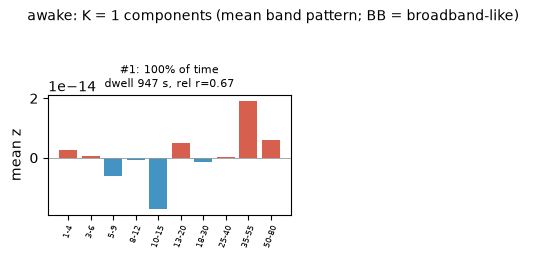

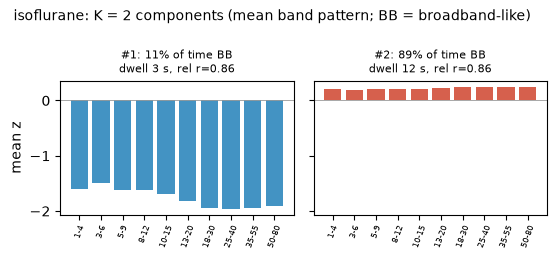

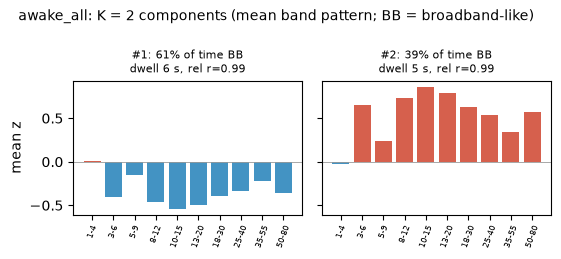

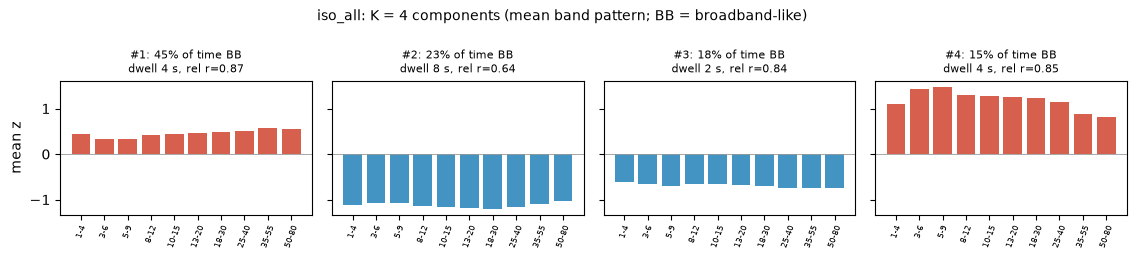

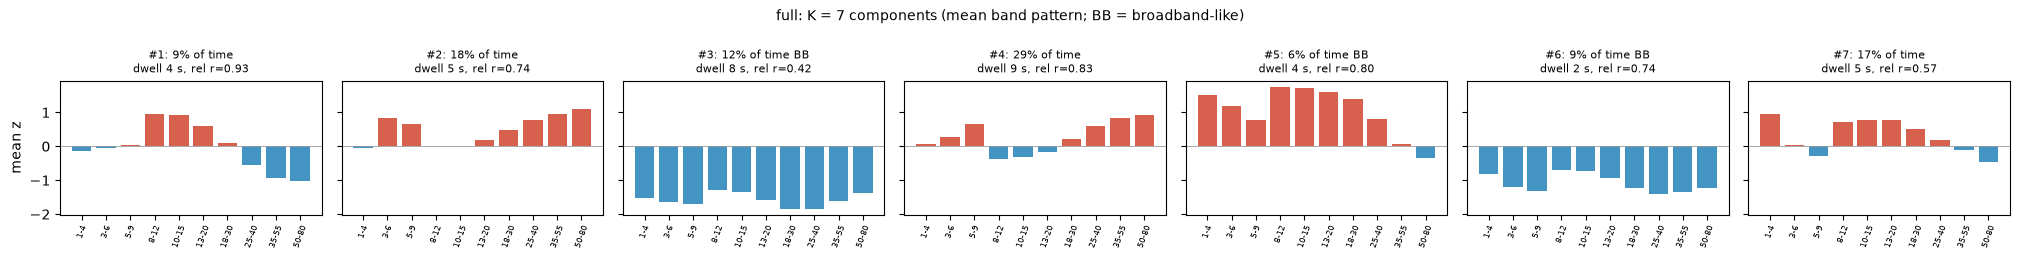

In [4]:
def bar(ax, mu, title):
    m = np.abs(mu).max() or 1
    ax.bar(range(len(names)), mu, color=np.where(mu >= 0, "#d6604d", "#4393c3"))
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_title(title, fontsize=8)
    ax.set_xticks(range(len(names)), names, rotation=70, fontsize=6)

for b in BINS:
    k = K_BEST[b]
    sub = comp[comp.bin == b].reset_index(drop=True)
    fig, axes = plt.subplots(1, max(k, 2), figsize=(2.9 * max(k, 2), 2.6), sharey=True, squeeze=False)
    for i in range(k):
        r = sub.loc[i]
        flag = " BB" if r.broadband else ""
        bar(axes[0, i], models[b].means_[i],
            f"#{i + 1}: {100 * r.weight:.0f}% of time{flag}\ndwell {r.median_dwell_s:.0f} s, rel r={r['best r with a relaxed pole']:.2f}")
    for ax in axes[0, k:]:
        ax.axis("off")
    axes[0, 0].set_ylabel("mean z")
    fig.suptitle(f"{b}: K = {k} components (mean band pattern; BB = broadband-like)", fontsize=10)
    fig.tight_layout(); save(fig, f"2_means_{b}"); plt.show()

### Same thing at fixed K = 2 … 6

The held-out choice is conservative. To see which patterns appear as K grows (and whether they split or stay put), here
are the means for each K in the spontaneous bins and the full recording. Unscaled z units, same y axis per row.

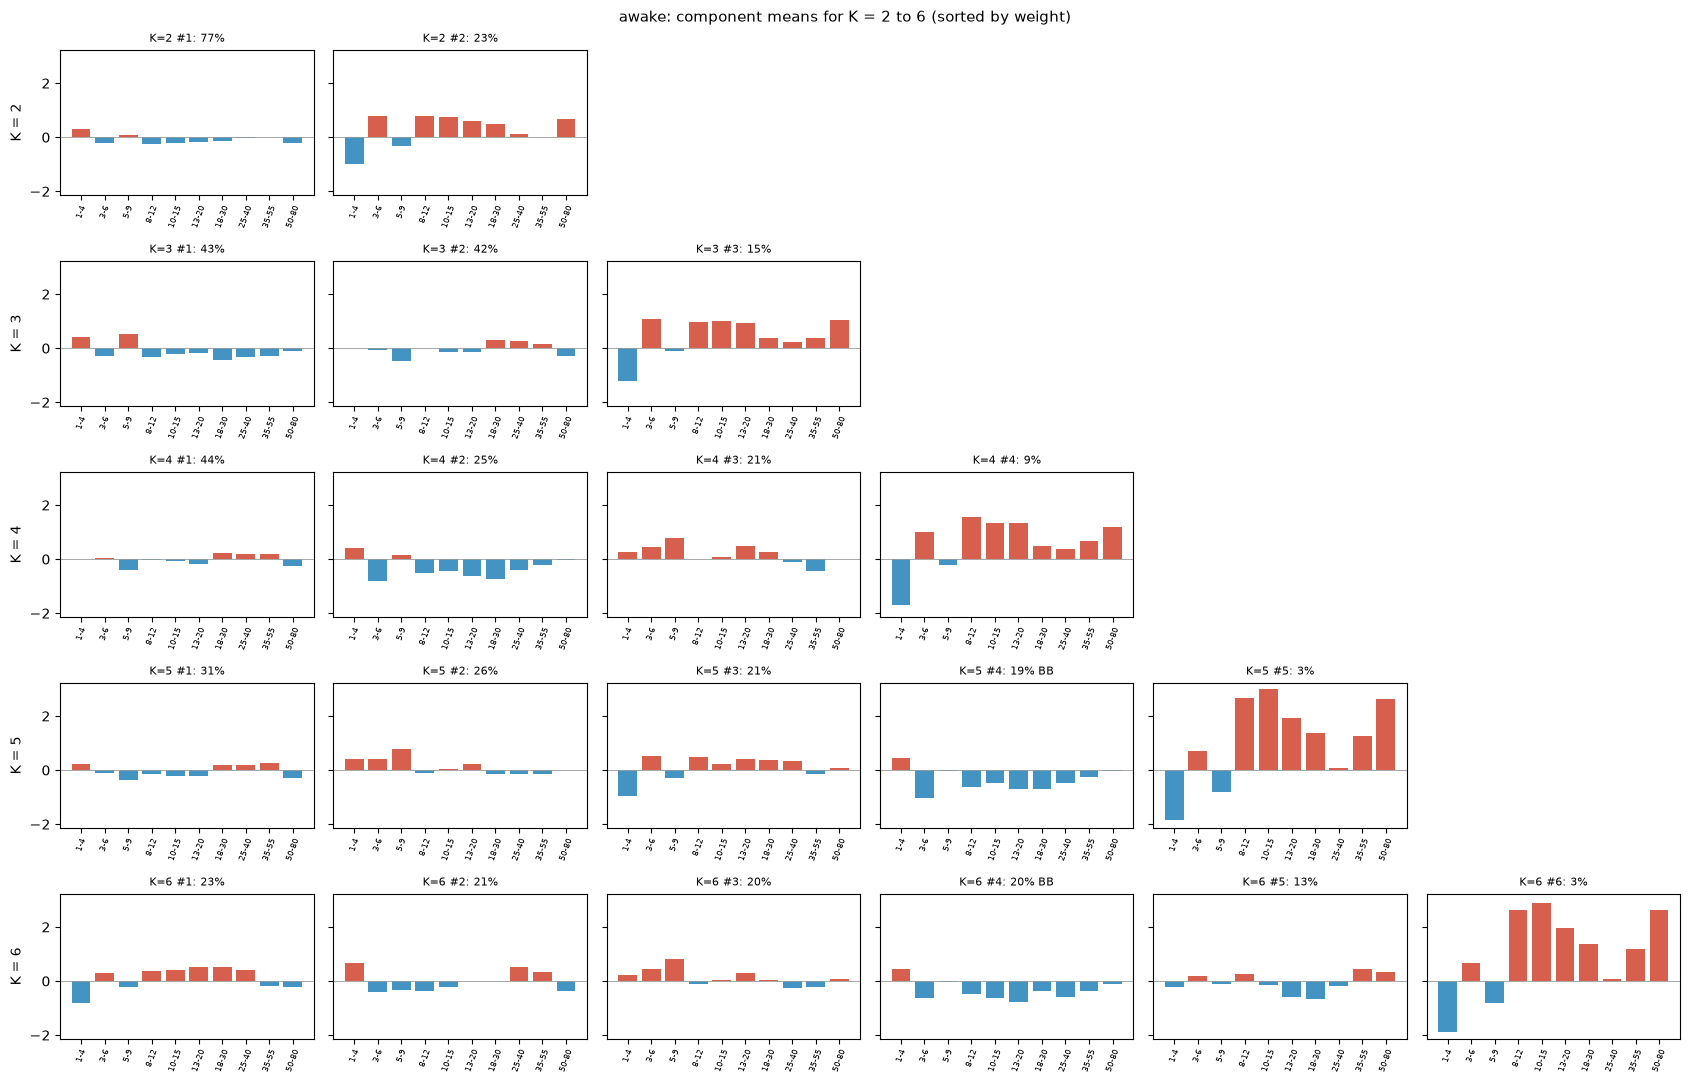

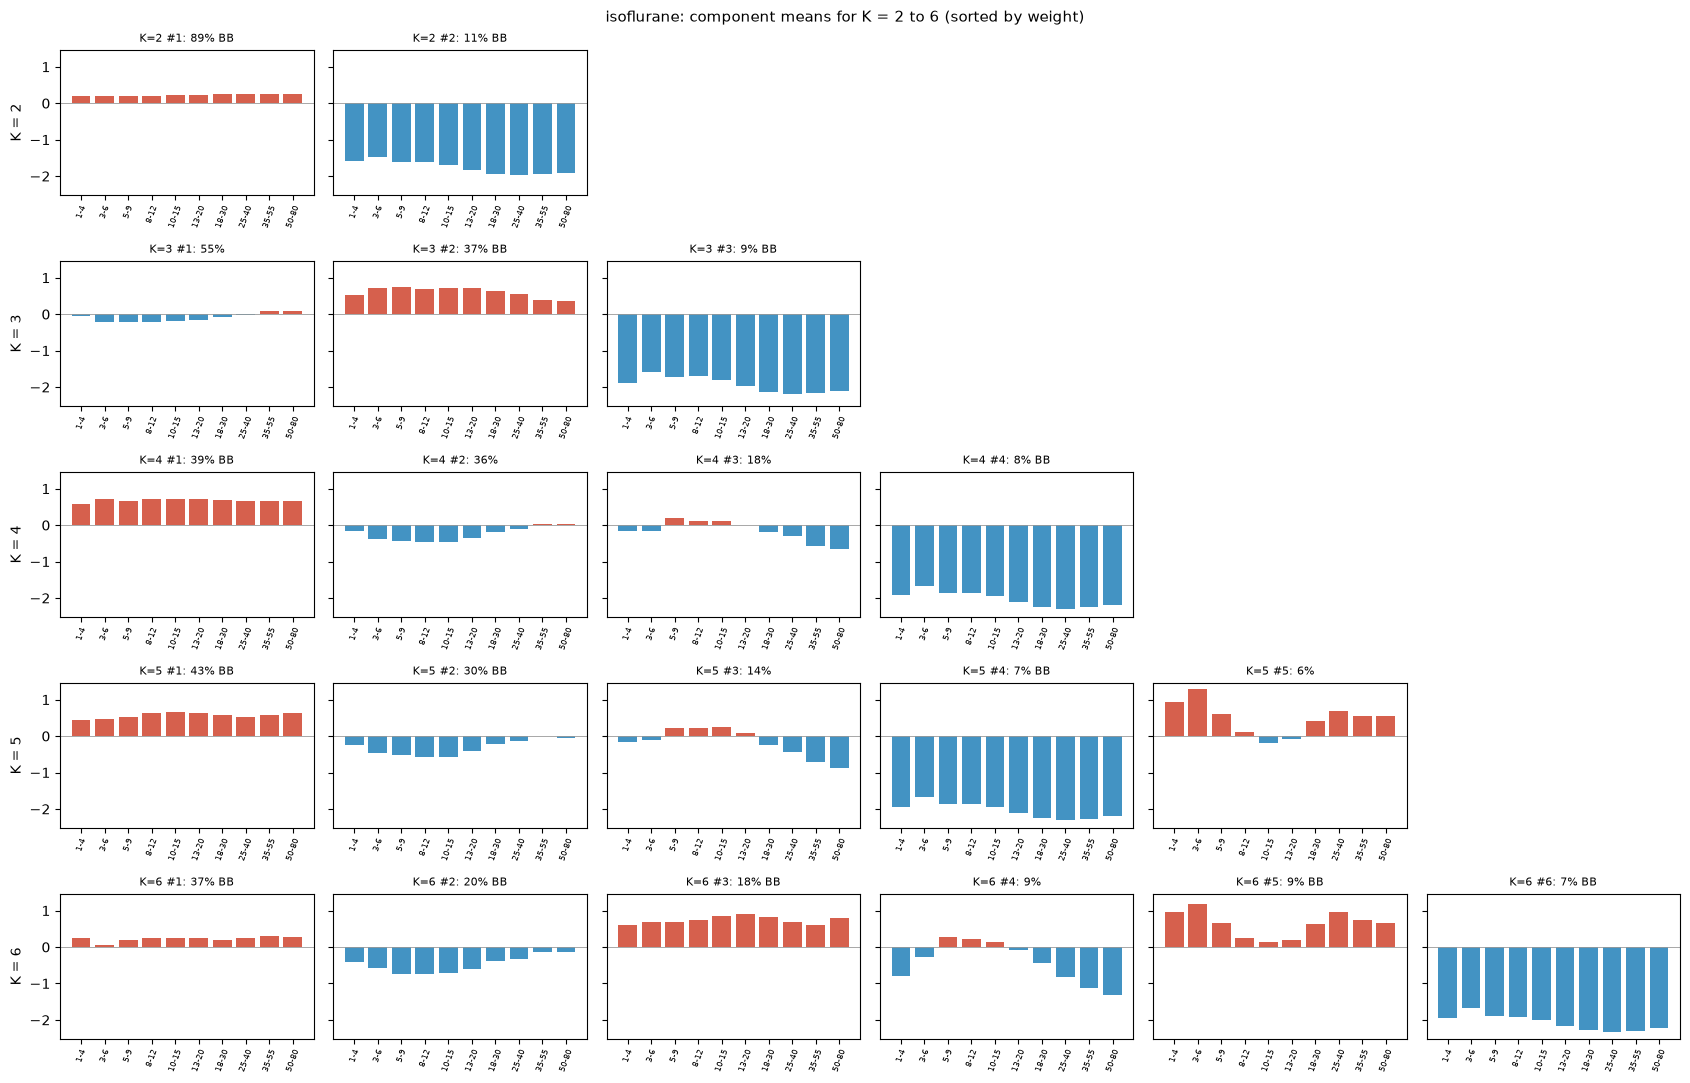

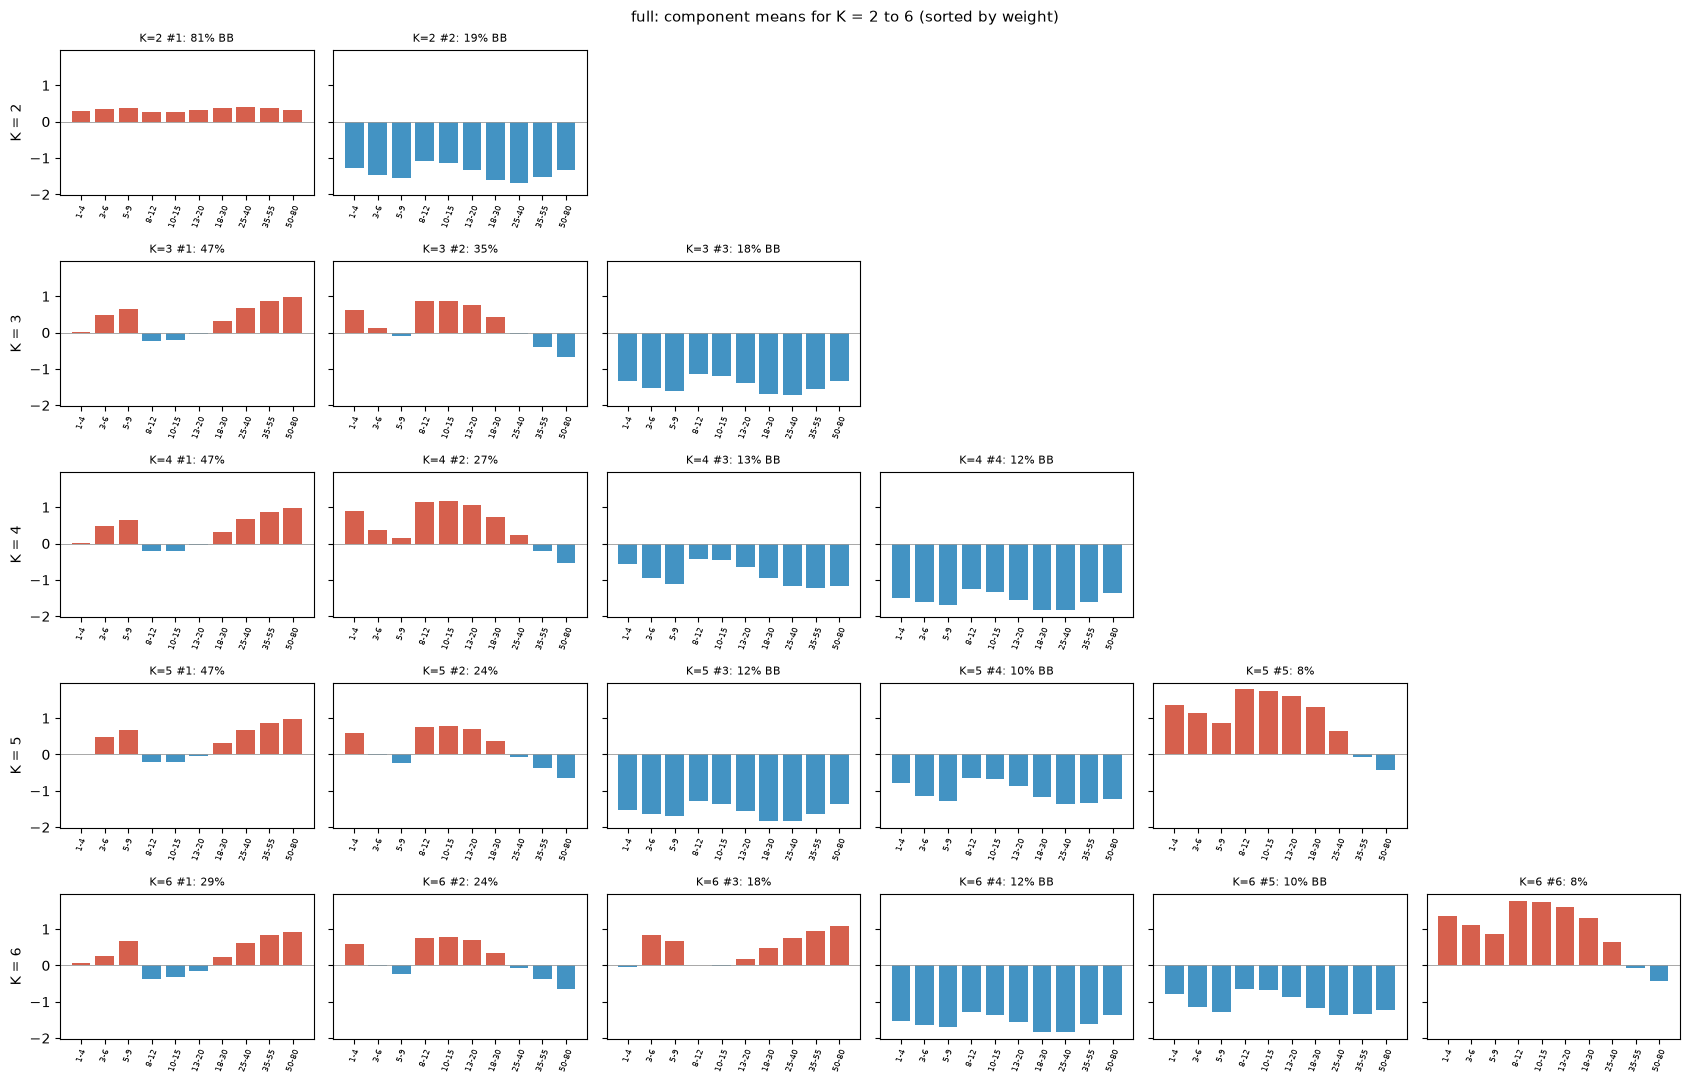

In [5]:
for b in ["awake", "isoflurane", "full"]:
    Z = Zs[b]
    fig, axes = plt.subplots(5, 6, figsize=(17, 11), sharey=True)
    for row, k in enumerate(range(2, 7)):
        gm = gx.fit(Z, k, n_init=3)
        order = np.argsort(-gm.weights_)
        for col in range(6):
            ax = axes[row, col]
            if col < k:
                i = order[col]
                mu = gm.means_[i]
                bb = " BB" if minority_sign_bands(mu) <= 1 else ""
                bar(ax, mu, f"K={k} #{col + 1}: {100 * gm.weights_[i]:.0f}%{bb}")
            else:
                ax.axis("off")
            if col == 0:
                ax.set_ylabel(f"K = {k}")
    fig.suptitle(f"{b}: component means for K = 2 to 6 (sorted by weight)", fontsize=11)
    fig.tight_layout(); save(fig, f"2_means_by_k_{b}"); plt.show()

## 3. Are there opponent pairs among the components?

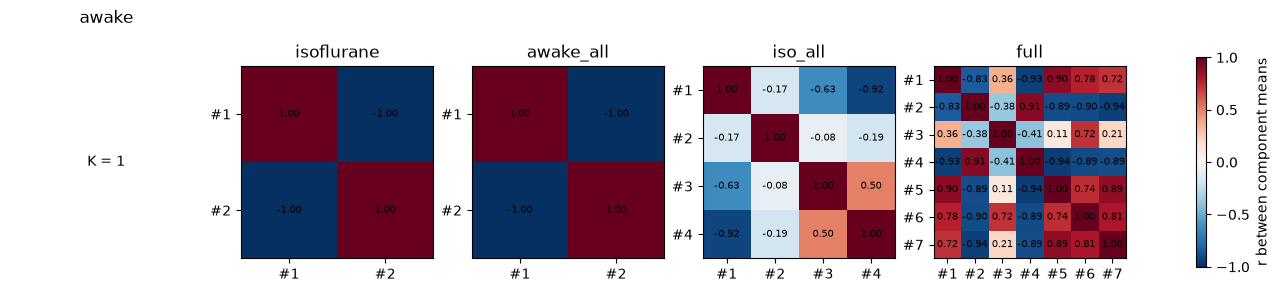

,bin,pair,r
0,isoflurane,#1 vs #2,-1.00
1,awake_all,#1 vs #2,-1.00
2,iso_all,#1 vs #3,-0.63
3,iso_all,#1 vs #4,-0.92
4,full,#1 vs #2,-0.83
5,full,#1 vs #4,-0.93
6,full,#2 vs #5,-0.89
7,full,#2 vs #6,-0.90
8,full,#2 vs #7,-0.94
9,full,#4 vs #5,-0.94


In [6]:
fig, axes = plt.subplots(1, len(BINS), figsize=(3.6 * len(BINS), 3.4))
for ax, b in zip(axes, BINS):
    k = K_BEST[b]
    if k < 2:
        ax.text(0.5, 0.5, "K = 1", ha="center", va="center"); ax.axis("off"); ax.set_title(b); continue
    C = np.corrcoef(models[b].means_)
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(k), [f"#{i + 1}" for i in range(k)]); ax.set_yticks(range(k), [f"#{i + 1}" for i in range(k)])
    ax.set_title(b)
fig.colorbar(im, ax=axes, shrink=0.8, label="r between component means")
save(fig, "3_component_correlations"); plt.show()
pd.DataFrame([{"bin": b, "pair": f"#{i + 1} vs #{j + 1}", "r": r} for b in BINS
              for i, j, r in gx.opponents(models[b].means_, -0.5)]).round(2)

Pairs with r ≤ −0.5 listed. An exact opponent pair would have r = −1; a GMM is free to find anything in between.

## 4. What the components look like in the data

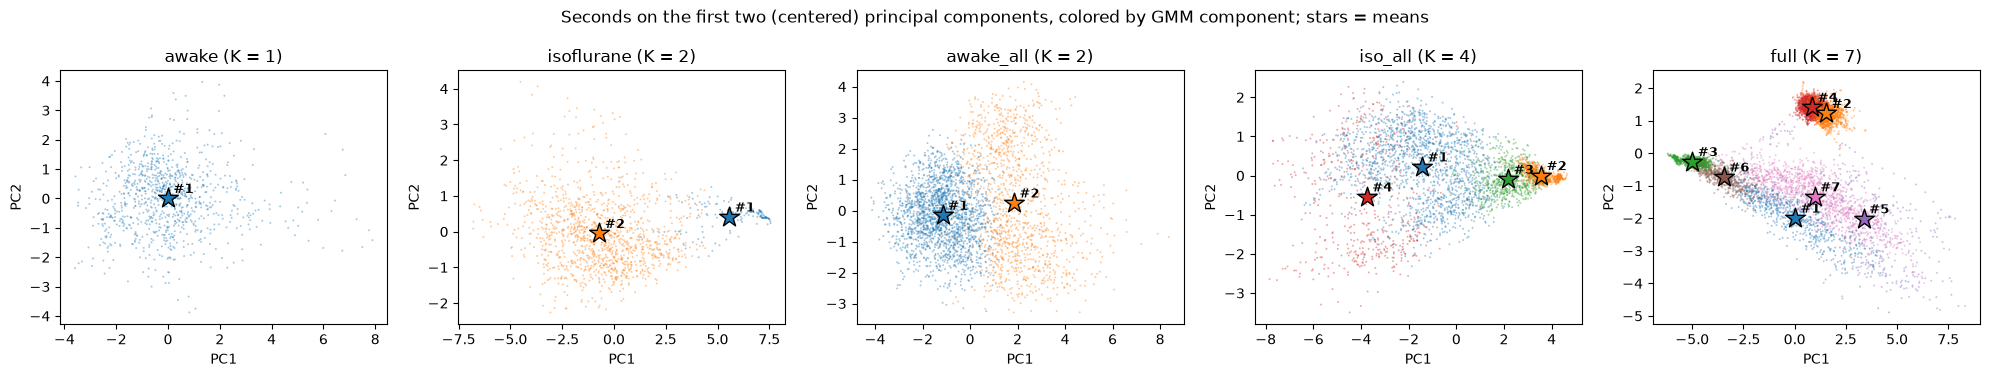

In [7]:
fig, axes = plt.subplots(1, len(BINS), figsize=(4 * len(BINS), 3.8))
for ax, b in zip(axes, BINS):
    Z = Zs[b]
    Zc = Z - Z.mean(0)
    _, _, vt = np.linalg.svd(Zc, full_matrices=False)
    P = Zc @ vt[:2].T
    M = (models[b].means_ - Z.mean(0)) @ vt[:2].T
    cmap = plt.get_cmap("tab10")
    ax.scatter(P[:, 0], P[:, 1], s=2, c=[cmap(l) for l in labels[b]], alpha=0.4, lw=0)
    for i, m in enumerate(M):
        ax.scatter(*m, marker="*", s=220, color=cmap(i), edgecolor="k", zorder=3)
        ax.annotate(f"#{i + 1}", m, xytext=(4, 4), textcoords="offset points", fontsize=9, weight="bold")
    ax.set_title(f"{b} (K = {K_BEST[b]})"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.suptitle("Seconds on the first two (centered) principal components, colored by GMM component; stars = means")
fig.tight_layout(); save(fig, "4_pc_scatter"); plt.show()

## 5. Components over time, with events

Top to bottom: isoflurane level and stimulus blocks (orange = electrical, blue = visual), running speed, pupil width,
then each component's responsibility (probability that each second belongs to it, 10-s smoothing). The `full` model sees
the whole recording; the spontaneous-bin models only their own seconds (gaps elsewhere).

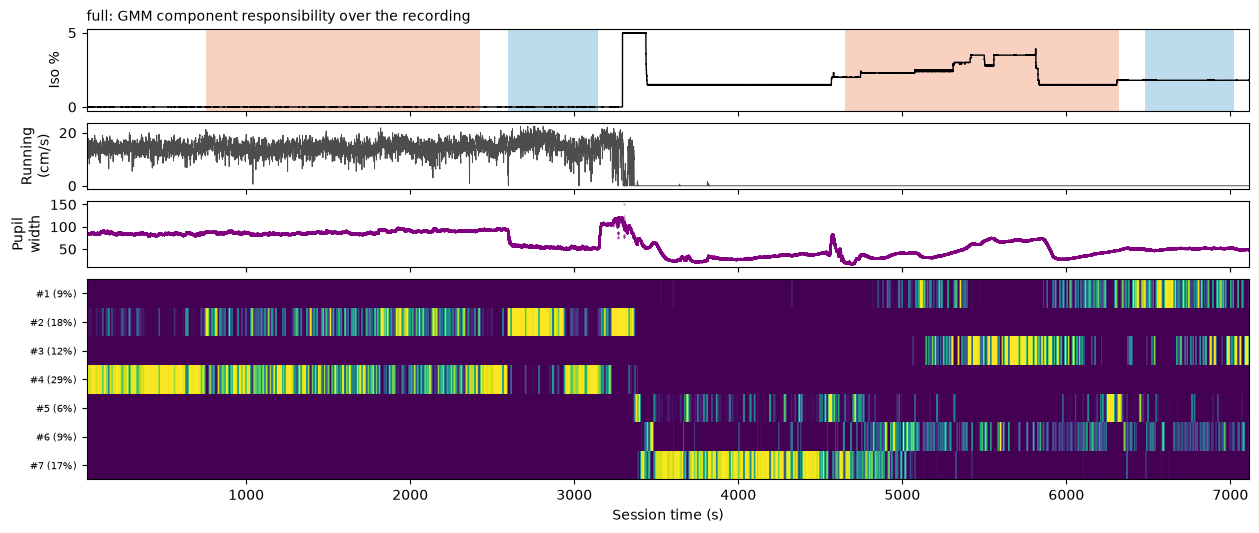

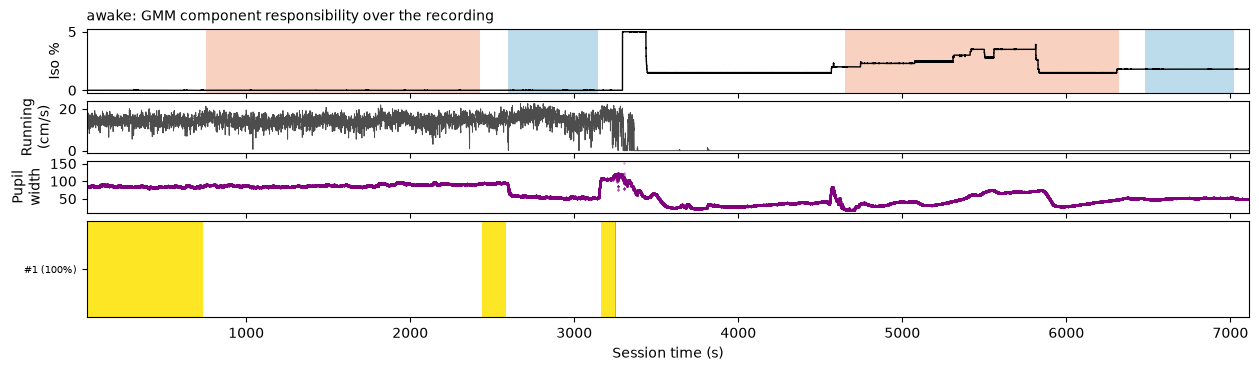

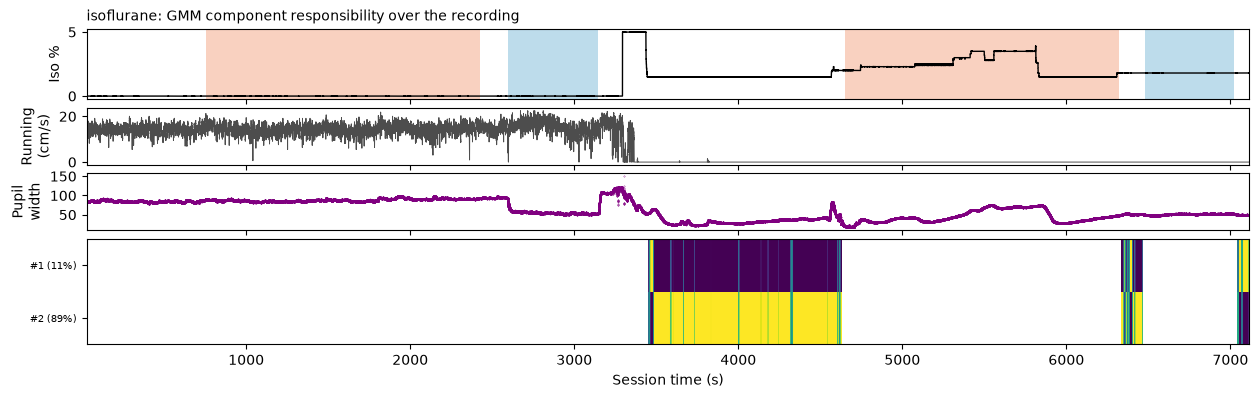

In [8]:
def smooth(v, n):
    return np.convolve(v, np.ones(n) / n, mode="same")

def timeline(b):
    T, R, k = Ts[b], resps[b], K_BEST[b]
    fig = plt.figure(figsize=(15, 3.4 + 0.35 * k))
    gs = fig.add_gridspec(4, 1, height_ratios=[1, 0.8, 0.8, max(1.5, 0.35 * k)], hspace=0.12)
    ax0 = fig.add_subplot(gs[0])
    ax0.plot(info.iso_t, info.iso_level, color="k", lw=1); ax0.set_ylabel("Iso %")
    for _, a, c in info.stim_blocks:
        ax0.axvspan(a, c, color="#f4a582", alpha=0.5, lw=0)
    for _, a, c in info.visual_blocks:
        ax0.axvspan(a, c, color="#92c5de", alpha=0.6, lw=0)
    ax0.set_title(f"{b}: GMM component responsibility over the recording", fontsize=10, loc="left")
    ax1 = fig.add_subplot(gs[1], sharex=ax0)
    ax1.plot(run_t, smooth(run_speed, 100), color="0.3", lw=0.7); ax1.set_ylabel("Running\n(cm/s)")
    ax2 = fig.add_subplot(gs[2], sharex=ax0)
    ax2.plot(pupil_t, pupil, ".", ms=0.5, color="purple"); ax2.set_ylabel("Pupil\nwidth")
    ax3 = fig.add_subplot(gs[3], sharex=ax0)
    grid = np.arange(t[0], t[-1] + 1)
    img = np.full((k, grid.size), np.nan)
    idx = np.searchsorted(grid, T)
    for i in range(k):
        img[i, idx] = smooth(R[:, i], 10)
    ax3.imshow(img, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="none",
               extent=[grid[0], grid[-1], k - 0.5, -0.5])
    ax3.set_yticks(range(k), [f"#{i + 1} ({100 * w:.0f}%)" for i, w in enumerate(models[b].weights_)], fontsize=7)
    ax3.set_xlabel("Session time (s)")
    for ax in (ax0, ax1, ax2):
        plt.setp(ax.get_xticklabels(), visible=False)
    ax0.set_xlim(t[0], t[-1])
    save(fig, f"5_timeline_{b}"); plt.show()

for b in ["full", "awake", "isoflurane"]:
    timeline(b)

Correlation of each `full`-model component's responsibility with running speed and pupil width, during spontaneous awake seconds only.

In [9]:
T = Ts["full"]
aw = np.isin(T, Ts["awake"])
run_ = np.interp(T[aw], run_t, smooth(run_speed, 100))
ok = np.isfinite(pupil)
pup_ = np.interp(T[aw], pupil_t[ok], pupil[ok])
R = resps["full"][aw]
used = R.mean(0) >= 0.01   # components that (almost) never occur in awake seconds give meaningless r
corr = lambda x: [np.corrcoef(R[:, i], x)[0, 1] if used[i] else np.nan for i in range(K_BEST["full"])]
pd.DataFrame({"share of awake seconds": R.mean(0),
              "r with running": corr(run_), "r with pupil": corr(pup_)},
             index=[f"#{i + 1}" for i in range(K_BEST["full"])]).round(2)

,share of awake seconds,r with running,r with pupil
#1,0.00,NaN,NaN
#2,0.13,0.14,0.6
#3,0.00,NaN,NaN
#4,0.87,-0.14,-0.6
#5,0.00,NaN,NaN
#6,0.00,NaN,NaN
#7,0.00,NaN,NaN


## 6. GMM along a motif axis: the bimodal histograms from the band EDA

These are the same axes and data as `band_eda.ipynb` figure `4_motif_axes_10` (10 log-spaced bands there, not the
report's bands; awake / isoflurane / full windows, stimuli included or excluded). Each second is projected onto the
motif axis, and a 1-D GMM with 2 and 3 components is fitted. Columns: histogram with both fits (title: the dip-test p
against band-shifted data, as in the EDA); seconds colored by state; the 2-component pole templates (high pole versus
minus the low pole); the 3-component ones. Templates are responsibility-weighted averages of the full band vectors.

With 2 components, high and minus-low are always identical in shape (r = 1.000) whatever the histogram looks like.

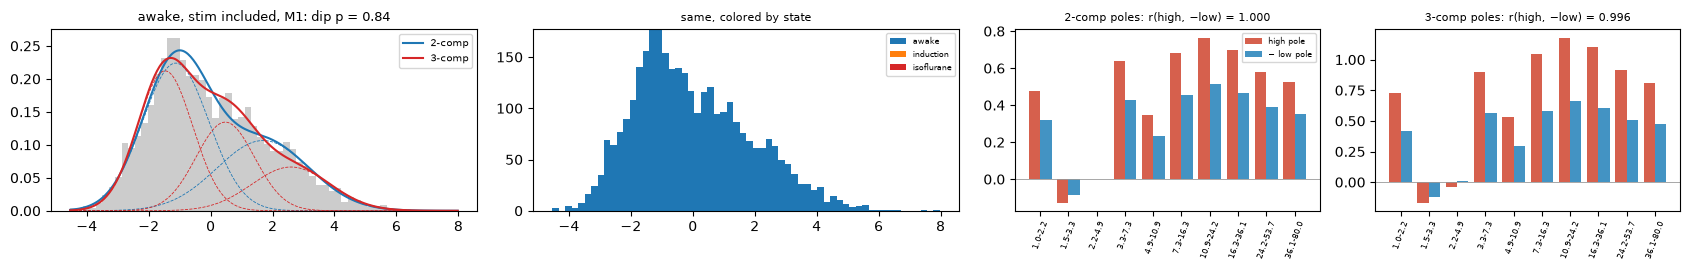

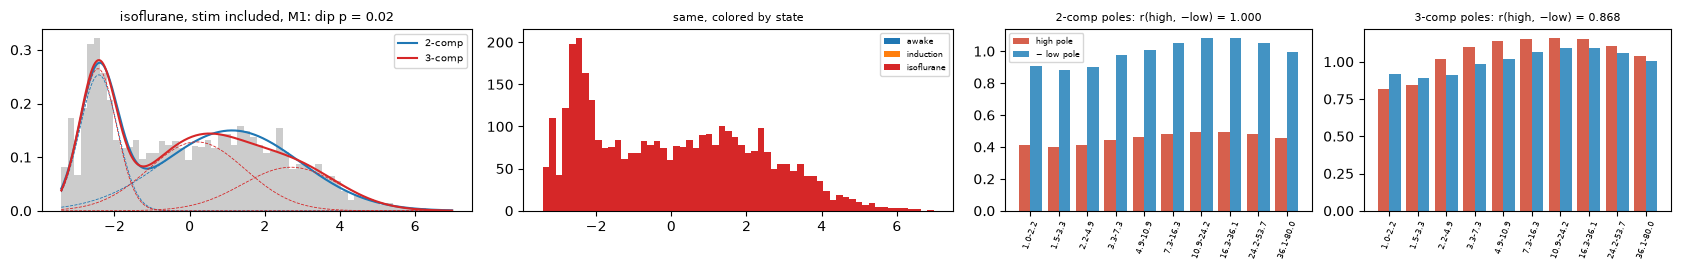

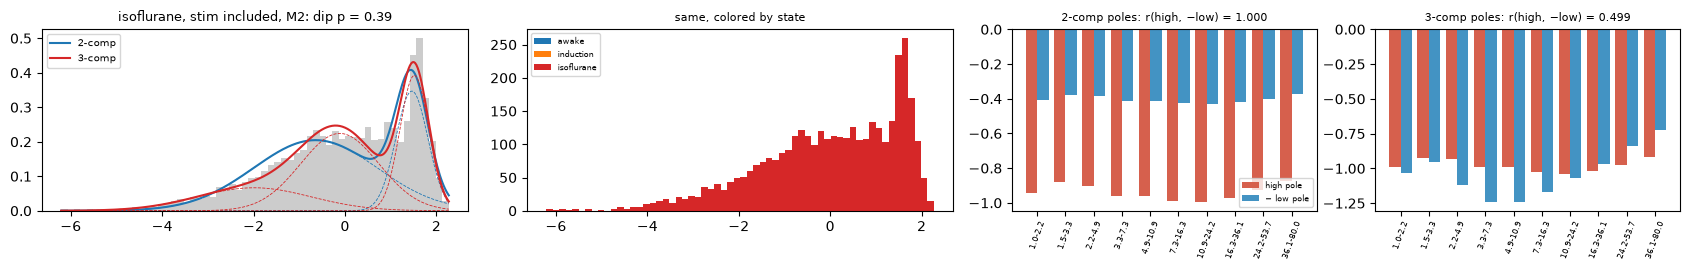

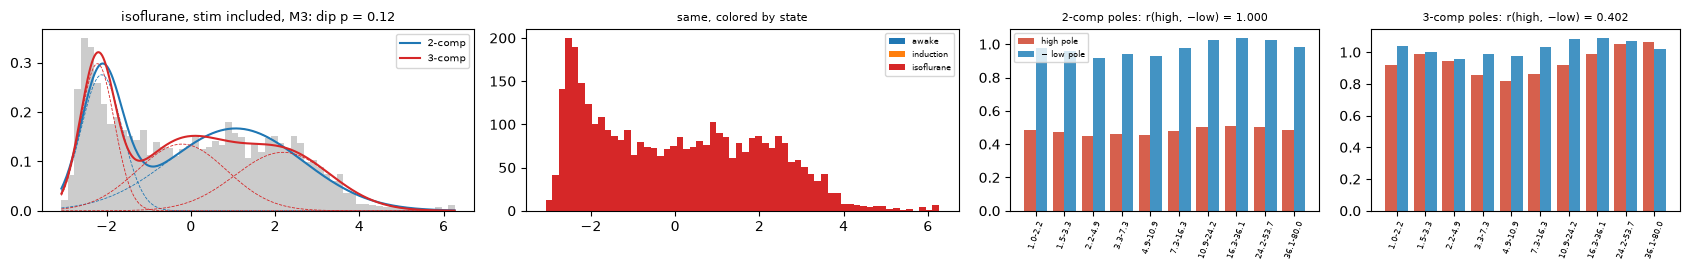

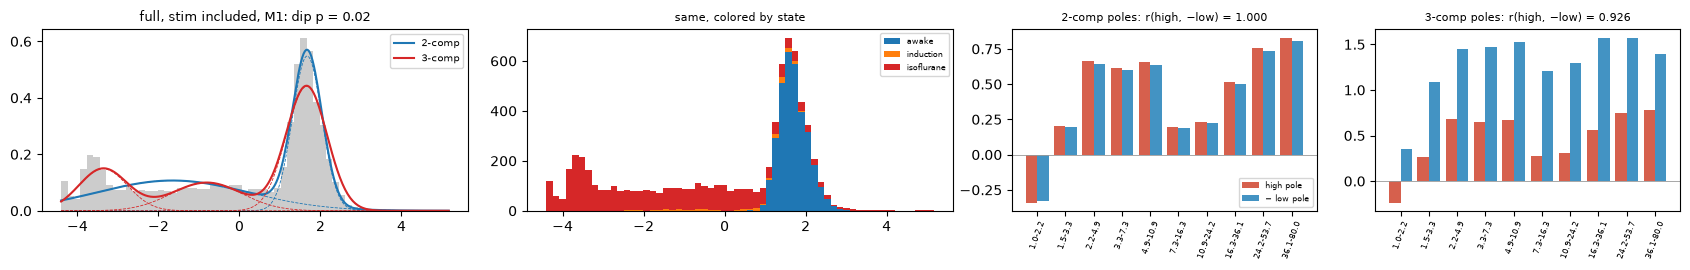

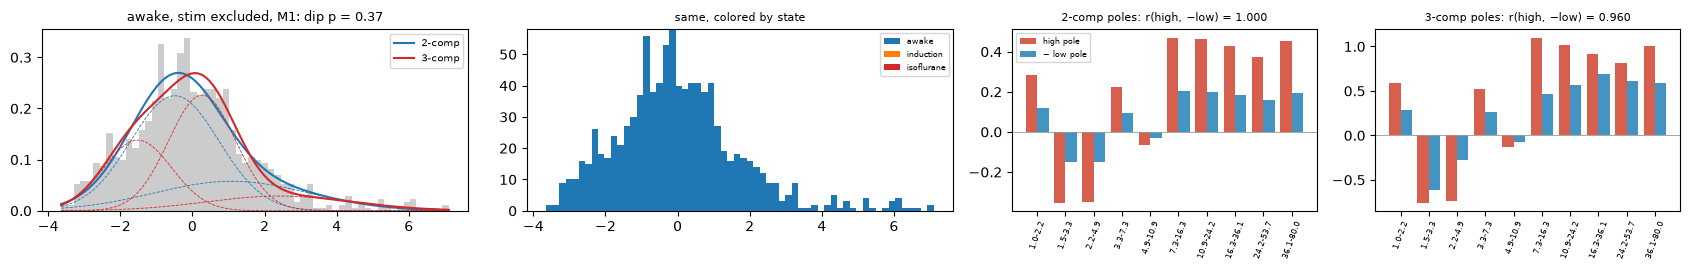

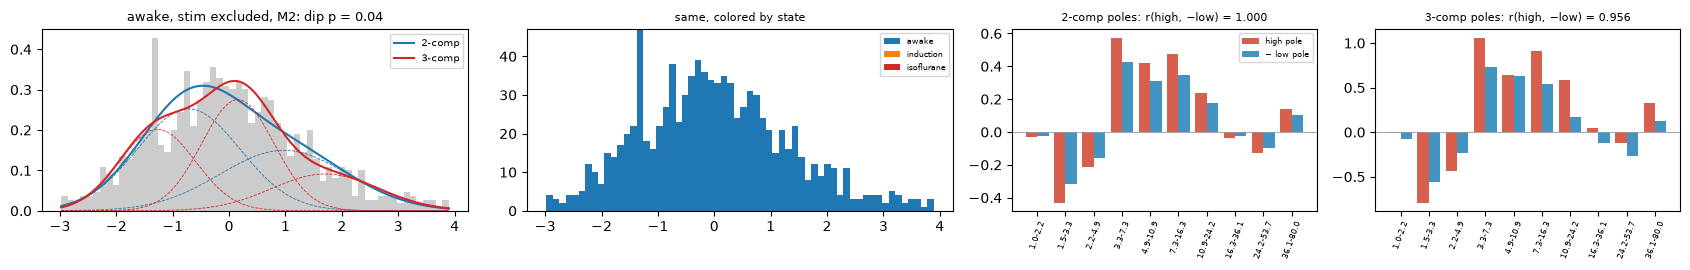

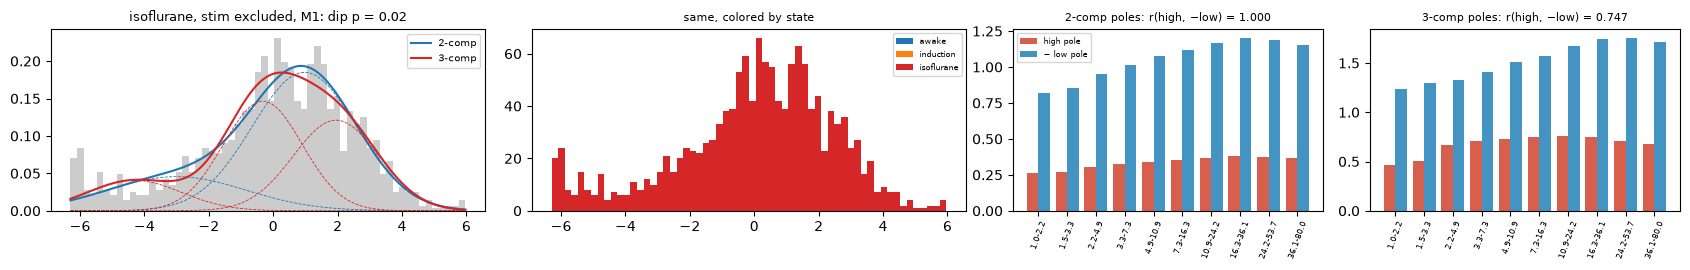

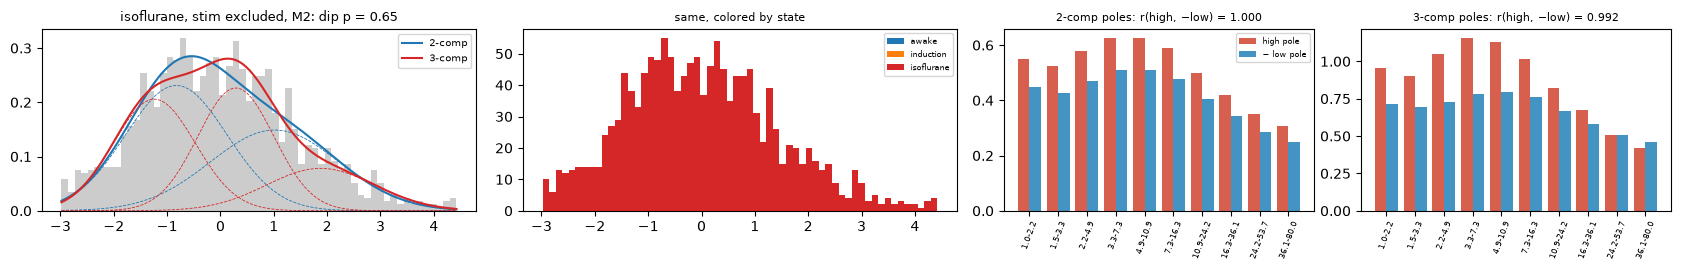

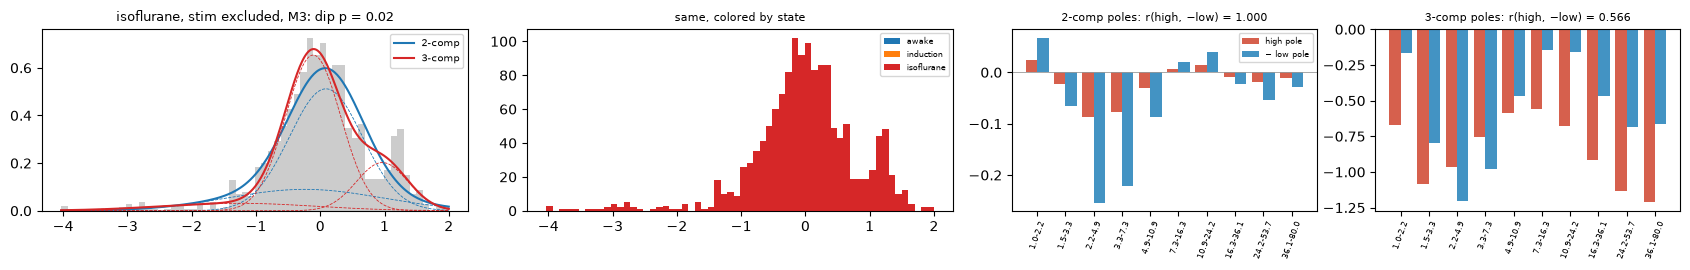

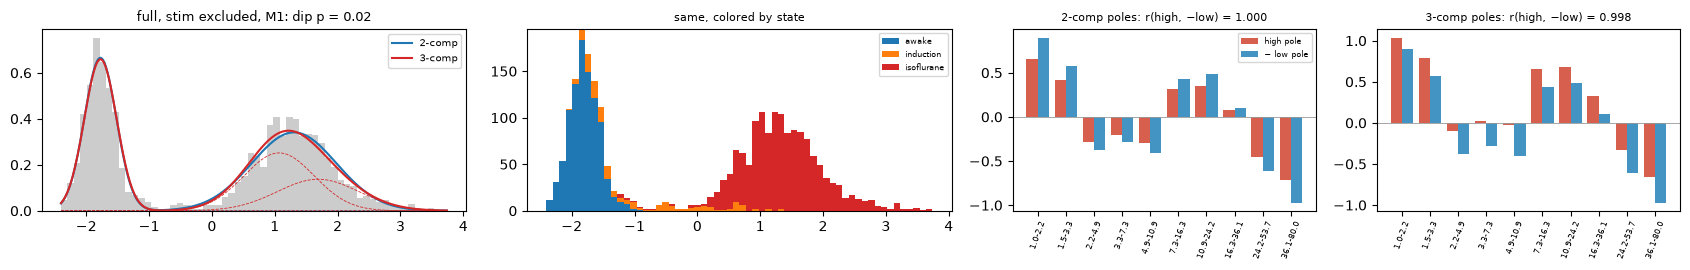

,stimulus,window,motif,dip p (vs band shift),"2-comp weights (low, high)","r(high, −low) 2-comp","3-comp weights (low, high)","r(high, −low) 3-comp","r(high, axis) 3-comp","r(−low, axis) 3-comp"
0,included,awake,1,0.843,"[0.6, 0.4]",1.0,"[0.47, 0.21]",0.996,0.995,0.992
1,included,isoflurane,1,0.020,"[0.32, 0.68]",1.0,"[0.32, 0.26]",0.868,0.993,0.861
2,included,isoflurane,2,0.392,"[0.69, 0.31]",1.0,"[0.21, 0.31]",0.499,0.432,0.928
3,included,isoflurane,3,0.118,"[0.33, 0.67]",1.0,"[0.3, 0.34]",0.402,0.895,0.328
4,included,full,1,0.020,"[0.5, 0.5]",1.0,"[0.22, 0.56]",0.926,0.974,0.912
5,excluded,awake,1,0.373,"[0.69, 0.31]",1.0,"[0.33, 0.15]",0.960,0.911,0.979
6,excluded,awake,2,0.039,"[0.58, 0.42]",1.0,"[0.34, 0.22]",0.956,0.916,0.971
7,excluded,isoflurane,1,0.020,"[0.24, 0.76]",1.0,"[0.15, 0.4]",0.747,0.915,0.920
8,excluded,isoflurane,2,0.647,"[0.55, 0.45]",1.0,"[0.4, 0.2]",0.992,0.977,0.984
9,excluded,isoflurane,3,0.020,"[0.27, 0.73]",1.0,"[0.09, 0.2]",0.566,0.706,0.880


In [10]:
from src import band_eda as be
CACHE = REPO / "data" / "processed" / "band_eda"
tests = pd.read_csv(REPO / "data" / "out" / "2026-11-08_band_eda" / "axis_tests.csv")
tests = tests[tests.bands == 10]
enames = be.band_names(be.band_set(10))
SC = {"awake": "#1f77b4", "induction": "#ff7f0e", "isoflurane": "#d62728"}

def gmm_poles(Z, s, k):
    gm = GaussianMixture(k, random_state=0, n_init=3).fit(s[:, None])
    R = gm.predict_proba(s[:, None])
    o = np.argsort(gm.means_.ravel())
    return gm, [(R[:, j] @ Z) / R[:, j].sum() for j in (o[0], o[-1])], [gm.weights_[o[0]], gm.weights_[o[-1]]]

def pair_bars(ax, hi, lo, title):
    ax.bar(np.arange(10) - 0.2, hi, 0.4, color="#d6604d", label="high pole")
    ax.bar(np.arange(10) + 0.2, -lo, 0.4, color="#4393c3", label="− low pole")
    ax.axhline(0, color="0.6", lw=0.6); ax.set_xticks(range(10), enames, rotation=70, fontsize=6)
    ax.set_title(title, fontsize=8)

rows = []
for stim in be.STIM:
    pieces = be.load(CACHE, 10, stim)
    for w in be.WINDOWS:
        d = be.window_data(pieces, info, w)
        axes_, version, _ = be.motif_axes(d, 10)
        for m in range(axes_.shape[1]):
            u = axes_[:, m] / np.linalg.norm(axes_[:, m])
            s = d.z @ u
            p = tests[(tests.stimulus == stim) & (tests.window == w) & (tests.motif == m + 1)].p_dip_axis
            p = float(p.iloc[0]) if len(p) else np.nan
            fig, axs = plt.subplots(1, 4, figsize=(17, 2.8), gridspec_kw={"width_ratios": [1.4, 1.4, 1, 1]})
            xs = np.linspace(s.min(), s.max(), 300)
            axs[0].hist(s, bins=60, density=True, color="0.8")
            res = {}
            for k, col in ((2, "C0"), (3, "C3")):
                gm, poles, wts = gmm_poles(d.z, s, k)
                axs[0].plot(xs, np.exp(gm.score_samples(xs[:, None])), color=col, label=f"{k}-comp")
                for j in range(k):
                    mu, sg = gm.means_[j, 0], np.sqrt(gm.covariances_[j].ravel()[0])
                    axs[0].plot(xs, gm.weights_[j] * np.exp(-(xs - mu) ** 2 / (2 * sg ** 2)) / (sg * np.sqrt(2 * np.pi)),
                                color=col, lw=0.6, ls="--")
                res[k] = (poles, wts)
            axs[0].legend(fontsize=7); axs[0].set_title(f"{w}, stim {stim}, M{m + 1}: dip p = {p:.2f}", fontsize=9)
            edges = np.linspace(s.min(), s.max(), 61)
            bottom = np.zeros(60)
            for st, c in SC.items():
                h, _ = np.histogram(s[d.state == st], edges)
                axs[1].bar(edges[:-1], h, np.diff(edges), bottom=bottom, align="edge", color=c, label=st, lw=0)
                bottom += h
            axs[1].legend(fontsize=6); axs[1].set_title("same, colored by state", fontsize=8)
            (lo2, hi2), w2 = res[2]; (lo3, hi3), w3 = res[3]
            r2, r3 = np.corrcoef(hi2, -lo2)[0, 1], np.corrcoef(hi3, -lo3)[0, 1]
            pair_bars(axs[2], hi2, lo2, f"2-comp poles: r(high, −low) = {r2:.3f}")
            pair_bars(axs[3], hi3, lo3, f"3-comp poles: r(high, −low) = {r3:.3f}")
            axs[2].legend(fontsize=6)
            fig.tight_layout(); save(fig, f"6_axis_gmm_{stim}_{w}_m{m + 1}"); plt.show()
            rows.append({"stimulus": stim, "window": w, "motif": m + 1, "dip p (vs band shift)": p,
                         "2-comp weights (low, high)": np.round(w2, 2), "r(high, −low) 2-comp": r2,
                         "3-comp weights (low, high)": np.round(w3, 2), "r(high, −low) 3-comp": r3,
                         "r(high, axis) 3-comp": np.corrcoef(hi3, u)[0, 1], "r(−low, axis) 3-comp": np.corrcoef(-lo3, u)[0, 1]})
axis_table = pd.DataFrame(rows)
axis_table.round(3)

## Conclusions

1. **Spontaneous awake has no cluster structure.** Held-out likelihood is best at K = 1, and the real curve is
   indistinguishable from the phase surrogates. The K = 2–6 means in the gallery are slices of one continuous,
   correlated cloud, not states. A GMM won't add awake candidates. The one recurring shape (delta down, alpha/beta and
   gamma up, 3–15% of seconds) is the cloud's tail.
2. **Spontaneous isoflurane: weak structure (K = 2, just above surrogates)**, and it is a broadband-low cluster
   (about 10% of seconds, every band about −2 z), likely suppression-like periods. Non-broadband shapes appear only at K ≥ 5,
   which the held-out data don't support.
3. **With stimuli and state changes included, structure is strong** (excess 3–5.5 nats per second). The 7 full-recording
   components are mostly stable across interleaved halves (r 0.8–0.98 for 5 of 7) and they segment the recording into
   epochs: spontaneous awake (#4), awake visual / pre-induction (#2), early isoflurane (#7), isoflurane (#5, #6),
   isoflurane electrical stimulation (#3, broadband high), late isoflurane (#1). The 10-D GMM is in effect an
   unsupervised **state segmenter**, and its awake and isoflurane components form near-opponent pairs (r ≈ −0.9).
4. **K = 2 is always mirrored**, in 10-D as along an axis (r = −1.00 in both K = 2 bins).
5. **Along a motif axis:** 7 of 11 axes are significantly bimodal. Bimodality comes from (a) awake vs isoflurane in the
   full window and (b) a compact extreme lump under isoflurane. The 2-component GMM always gives mirrored pole shapes
   (r = 1.000 in all 11). The 3-component GMM gives asymmetric poles on the isoflurane axes (r 0.40–0.87), but the
   asymmetry is mostly an overall broadband level swept into each pole.

**Implication:** a GMM is useful as a state/epoch labeller and as a soft expression measure, not as a source of
new spontaneous motifs on this channel.